<a href="https://colab.research.google.com/github/brotheramin/MachineLearning/blob/main/brisbaneRiver.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

# Install compatible versions together.
# Do not use --no-deps.

%pip install --upgrade --force-reinstall --no-cache-dir pgmpy scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 67.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 216.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 493.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 349.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 234.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 258.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 263.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 838.5/838.5 kB 316.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 280.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 291.2 MB/s  0:00:00
  Attempting uninstall: wrapt
    Found existing installation: wrapt 2.5.2
    Uninstalling wrapt-2.5.2:
      Successfully uninstalled wrapt-2.5.2
  Attempting uninstall: tzdata
    Found existing installation: tzdata 2026.6
    Unins

In [1]:

import numpy as np
import pandas as pd
import sklearn
import pgmpy

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("pgmpy:", pgmpy.__version__)

print("ALL IMPORTS SUCCESSFUL!")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


NumPy: 2.5.5
Pandas: 3.1.1
Scikit-learn: 1.9.1
pgmpy: 1.1.2
ALL IMPORTS SUCCESSFUL!


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Upload your Brisbane River water-quality CSV file.


Saving brisbane_water_quality.csv to brisbane_water_quality (4).csv

Dataset loaded successfully.
Original dataset shape: (30894, 20)

Available columns:
['Timestamp', 'Record number', 'Average Water Speed', 'Average Water Direction', 'Chlorophyll', 'Chlorophyll [quality]', 'Temperature', 'Temperature [quality]', 'Dissolved Oxygen', 'Dissolved Oxygen [quality]', 'Dissolved Oxygen (%Saturation)', 'Dissolved Oxygen (%Saturation) [quality]', 'pH', 'pH [quality]', 'Salinity', 'Salinity [quality]', 'Specific Conductance', 'Specific Conductance [quality]', 'Turbidity', 'Turbidity [quality]']

Measurement variables identified:
['Speed', 'Direction', 'Temp', 'DO', 'Chlorophyll', 'DO_Saturation', 'pH', 'Salinity', 'Conductance', 'Turbidity']

Dataset after 30-minute resampling:
(15717, 20)

Date range:
2023-08-04 23:00:00 to 2024-06-27 09:00:00

Training cutoff: 2024-04-22 21:30:00

Risk indicators used:
['DO', 'Turbidity', 'Chlorophyll', 'pH']

FutureRisk class distribution:
FutureRisk
Moderat

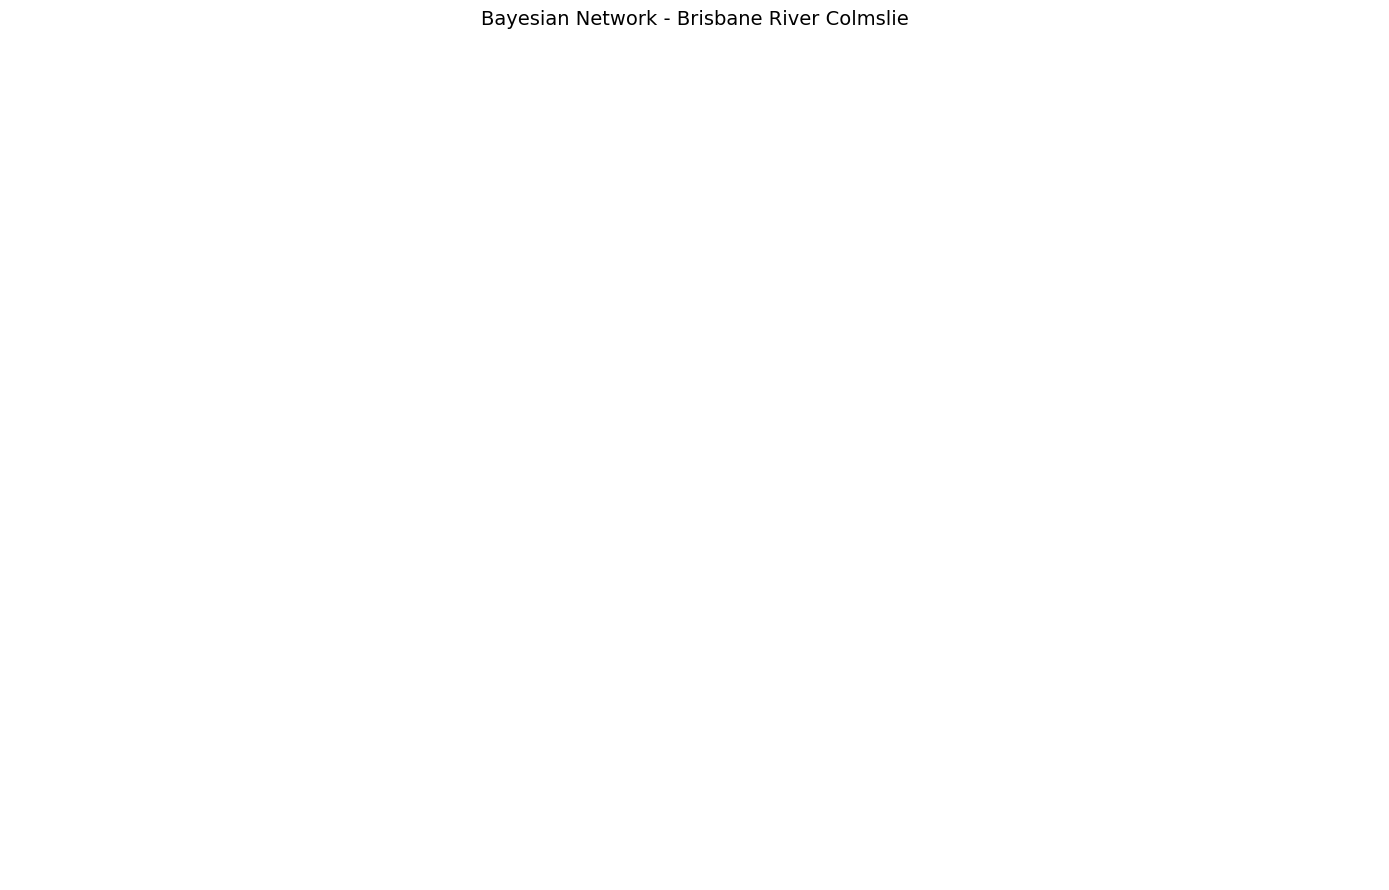


Training Bayesian Network...

Bayesian Network trained successfully.

Model validation:
True

Conditional Probability Distributions:
+--------------+----------+
| Temp(Low)    | 0.333391 |
+--------------+----------+
| Temp(Medium) | 0.333304 |
+--------------+----------+
| Temp(High)   | 0.333304 |
+--------------+----------+
+------------+---------------------+---------------------+---------------------+
| Temp       | Temp(Low)           | Temp(Medium)        | Temp(High)          |
+------------+---------------------+---------------------+---------------------+
| DO(Low)    | 0.17866828226876694 | 0.3259746630883329  | 0.4963495224078724  |
+------------+---------------------+---------------------+---------------------+
| DO(Medium) | 0.2713634527724886  | 0.42804374801604483 | 0.30130147461980206 |
+------------+---------------------+---------------------+---------------------+
| DO(High)   | 0.5499682649587445  | 0.24598158889562233 | 0.20234900297232564 |
+------------+--------

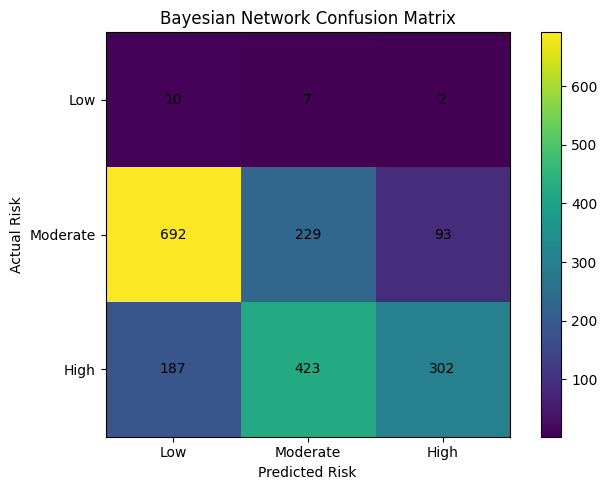


Illustrative decision cost matrix:
          Routine Monitoring  Increase Monitoring  Confirmatory Sampling  \
Low                        0                    2                      5   
Moderate                   5                    2                      4   
High                      20                   10                      4   

          Investigate Potential Source  
Low                                 10  
Moderate                             7  
High                                 8  

FINAL BAYESIAN NETWORK RESULTS
             Timestamp ActualRisk PredictedRisk       Low  Moderate      High  \
0  2024-05-17 20:00:00        Low           Low  0.799774  0.176546  0.023679   
1  2024-05-17 20:30:00   Moderate           Low  0.906428  0.093253  0.000319   
2  2024-05-17 21:00:00       High      Moderate  0.363599  0.635986  0.000415   
3  2024-05-17 21:30:00       High      Moderate  0.363599  0.635986  0.000415   
4  2024-05-17 22:00:00       High      Moderate  0.002271 

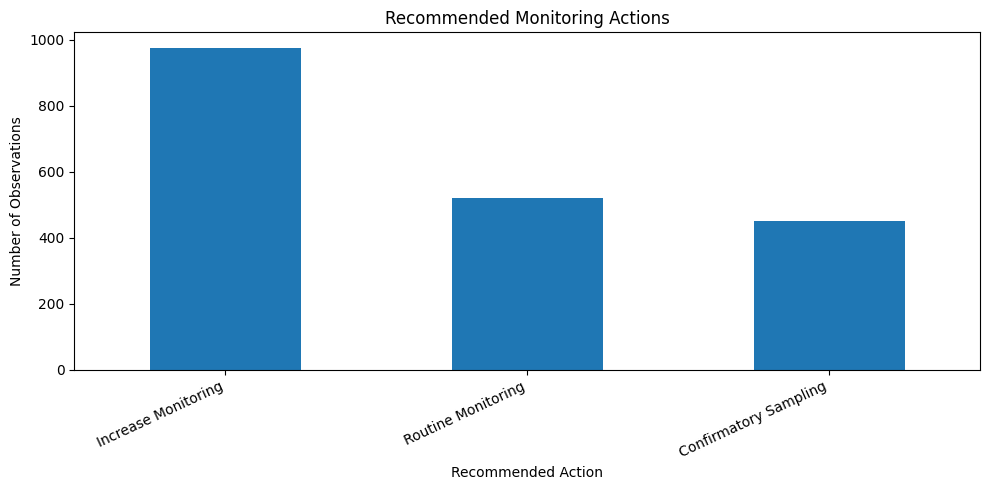

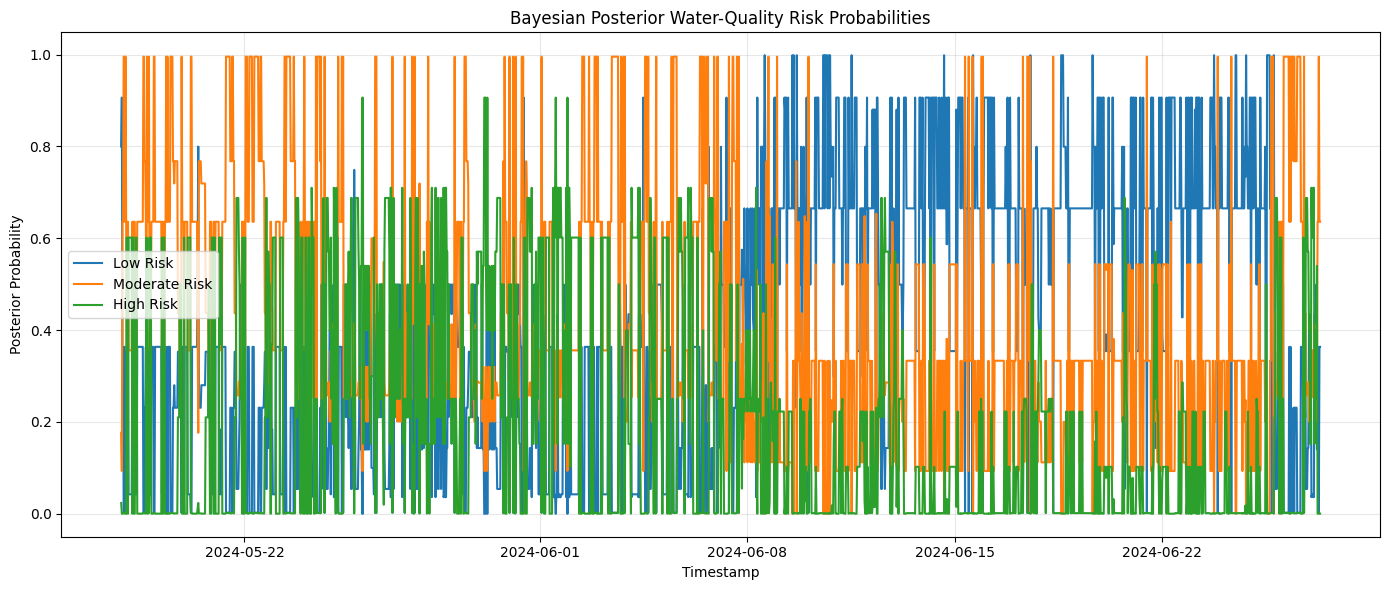


Results exported successfully:
Bayesian_Network_Colmslie_Results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT SUMMARY
Dataset: Brisbane River - Colmslie
Model: Bayesian Network
Prediction target: FutureRisk
Prediction horizon: 30 minutes
Training samples: 11542
Testing samples: 1945
Accuracy: 0.2781
Macro F1-score: 0.2524

Predicted risk distribution:
PredictedRisk
Low         889
Moderate    659
High        397
Name: count, dtype: int64

Recommended actions:
RecommendedAction
Increase Monitoring      974
Routine Monitoring       520
Confirmatory Sampling    451
Name: count, dtype: int64

Bayesian Network analysis completed.


In [5]:

# ============================================================
# BAYESIAN NETWORK - BRISBANE RIVER COLMSLIE WATER QUALITY
# ============================================================
# Dataset: Brisbane River Colmslie Site Water Quality Buoy
# Objective: Predict future water-quality deterioration risk
#
# Important:
# FutureRisk is a constructed research label, not an official
# Queensland Government pollution classification.
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from google.colab import files

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination


# ============================================================
# 2. UPLOAD DATASET
# ============================================================

print("Upload your Brisbane River water-quality CSV file.")

uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

df = pd.read_csv(file_name)

print("\nDataset loaded successfully.")
print("Original dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())


# ============================================================
# 3. CLEAN COLUMN NAMES AND IDENTIFY VARIABLES
# ============================================================

df.columns = df.columns.str.strip()

# Expected columns from the Colmslie dataset
column_mapping = {
    "Average Water Speed": "Speed",
    "Average Water Direction": "Direction",
    "Temperature": "Temp",
    "Dissolved Oxygen": "DO",
    "Chlorophyll": "Chlorophyll",
    "Dissolved Oxygen (%Saturation)": "DO_Saturation",
    "pH": "pH",
    "Salinity": "Salinity",
    "Specific Conductance": "Conductance",
    "Turbidity": "Turbidity"
}

available_mapping = {
    original: renamed
    for original, renamed in column_mapping.items()
    if original in df.columns
}

df = df.rename(columns=available_mapping)

if "Timestamp" not in df.columns:
    raise ValueError("The dataset does not contain a Timestamp column.")

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce"
)

df = df.dropna(subset=["Timestamp"])

# Convert measurement columns to numeric
measurement_columns = list(available_mapping.values())

for col in measurement_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep only measurement columns that exist
measurement_columns = [
    col for col in measurement_columns
    if col in df.columns
]

if len(measurement_columns) < 3:
    raise ValueError(
        "Not enough measurement columns were found. "
        "Check the dataset column names."
    )

print("\nMeasurement variables identified:")
print(measurement_columns)


# ============================================================
# 4. HANDLE DUPLICATE TIMESTAMPS AND RESAMPLE
# ============================================================

df = df.sort_values("Timestamp")
df = df.set_index("Timestamp")

# Handle water direction using circular averaging
# This avoids incorrect averages around 0/360 degrees.

if "Direction" in df.columns:

    direction_radians = np.deg2rad(df["Direction"])

    df["Direction_sin"] = np.sin(direction_radians)
    df["Direction_cos"] = np.cos(direction_radians)

    df = df.drop(columns=["Direction"])

# Aggregate measurements into 30-minute intervals
df = df.resample("30min").mean()

# Reconstruct circular mean direction
if (
    "Direction_sin" in df.columns
    and "Direction_cos" in df.columns
):

    df["Direction"] = (
        np.rad2deg(
            np.arctan2(
                df["Direction_sin"],
                df["Direction_cos"]
            )
        ) + 360
    ) % 360

    df = df.drop(
        columns=["Direction_sin", "Direction_cos"]
    )

df = df.reset_index()

print("\nDataset after 30-minute resampling:")
print(df.shape)

print("\nDate range:")
print(df["Timestamp"].min(), "to", df["Timestamp"].max())


# ============================================================
# 5. CHRONOLOGICAL TRAIN/TEST SPLIT
# ============================================================

split_position = int(len(df) * 0.80)

if split_position < 10 or split_position >= len(df) - 1:
    raise ValueError("Not enough observations for train/test splitting.")

split_time = df.iloc[split_position]["Timestamp"]

print("\nTraining cutoff:", split_time)

# Thresholds are calculated using training-period observations only.
baseline = df[df["Timestamp"] < split_time].copy()


# ============================================================
# 6. CREATE FUTURE WATER-QUALITY RISK LABEL
# ============================================================
# The model predicts the next 30-minute observation.
#
# Risk indicators:
# 1. Low dissolved oxygen
# 2. High turbidity
# 3. High chlorophyll
# 4. Unusual pH
#
# These are research indicators, not regulatory thresholds.


risk_variables = {}

if "DO" in df.columns and baseline["DO"].notna().any():
    risk_variables["DO"] = {
        "threshold": baseline["DO"].quantile(0.25),
        "type": "low"
    }

if "Turbidity" in df.columns and baseline["Turbidity"].notna().any():
    risk_variables["Turbidity"] = {
        "threshold": baseline["Turbidity"].quantile(0.75),
        "type": "high"
    }

if "Chlorophyll" in df.columns and baseline["Chlorophyll"].notna().any():
    risk_variables["Chlorophyll"] = {
        "threshold": baseline["Chlorophyll"].quantile(0.75),
        "type": "high"
    }

if "pH" in df.columns and baseline["pH"].notna().any():
    risk_variables["pH"] = {
        "lower": baseline["pH"].quantile(0.10),
        "upper": baseline["pH"].quantile(0.90),
        "type": "range"
    }

if len(risk_variables) < 3:
    raise ValueError(
        "At least three usable risk indicators are required. "
        "Check DO, Turbidity, Chlorophyll and pH."
    )

print("\nRisk indicators used:")
print(list(risk_variables.keys()))

# Future measurements: next 30-minute interval
future = df[measurement_columns].shift(-1)

# Verify that the next available row is exactly 30 minutes later
next_timestamp = df["Timestamp"].shift(-1)

valid_next = (
    next_timestamp - df["Timestamp"]
) == pd.Timedelta(minutes=30)

risk_scores = pd.Series(
    0,
    index=df.index,
    dtype="int64"
)

available_scores = pd.Series(
    0,
    index=df.index,
    dtype="int64"
)

for variable, settings in risk_variables.items():

    future_values = future[variable]

    if settings["type"] == "low":

        condition = (
            future_values < settings["threshold"]
        )

    elif settings["type"] == "high":

        condition = (
            future_values > settings["threshold"]
        )

    else:

        condition = (
            (future_values < settings["lower"])
            |
            (future_values > settings["upper"])
        )

    available = future_values.notna() & valid_next

    risk_scores += (
        condition.fillna(False) & available
    ).astype(int)

    available_scores += available.astype(int)

# Require at least three available indicators,
# or all indicators if fewer than three exist.
minimum_available = min(3, len(risk_variables))

valid_label = (
    valid_next
    & (available_scores >= minimum_available)
)

# IMPORTANT FIX:
# Create FutureRisk as object dtype before assigning text.
df["FutureRisk"] = pd.Series(
    index=df.index,
    dtype="object"
)

df.loc[
    valid_label & (risk_scores == 0),
    "FutureRisk"
] = "Low"

df.loc[
    valid_label & (risk_scores == 1),
    "FutureRisk"
] = "Moderate"

df.loc[
    valid_label & (risk_scores >= 2),
    "FutureRisk"
] = "High"

print("\nFutureRisk class distribution:")
print(df["FutureRisk"].value_counts(dropna=True))


# ============================================================
# 7. SELECT MODEL FEATURES
# ============================================================

candidate_features = [
    "Temp",
    "DO",
    "Chlorophyll",
    "Speed",
    "Direction",
    "Salinity",
    "Conductance",
    "Turbidity",
    "pH",
    "DO_Saturation"
]

feature_columns = [
    col for col in candidate_features
    if col in df.columns
    and df[col].notna().any()
]

if len(feature_columns) < 2:
    raise ValueError("Not enough usable model features.")

print("\nFeatures selected:")
print(feature_columns)


# ============================================================
# 8. PREPARE TRAINING AND TESTING DATA
# ============================================================

# Training observations must have their next observation
# inside the training period.
train_mask = (
    (df["Timestamp"] < split_time)
    &
    (df["Timestamp"] + pd.Timedelta(minutes=30) < split_time)
    &
    df["FutureRisk"].notna()
)

test_mask = (
    (df["Timestamp"] >= split_time)
    &
    df["FutureRisk"].notna()
)

train_data = df.loc[
    train_mask,
    feature_columns + ["FutureRisk"]
].copy()

test_data = df.loc[
    test_mask,
    feature_columns + ["FutureRisk"]
].copy()

if train_data.empty or test_data.empty:
    raise ValueError(
        "Training or testing data is empty. "
        "Check the timestamp frequency and missing values."
    )

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))


# ============================================================
# 9. HANDLE MISSING VALUES
# ============================================================

# Imputation values are learned from training data only.
for col in feature_columns:

    train_data[col] = pd.to_numeric(
        train_data[col],
        errors="coerce"
    )

    test_data[col] = pd.to_numeric(
        test_data[col],
        errors="coerce"
    )

    if train_data[col].notna().any():

        median_value = train_data[col].median()

        train_data[col] = train_data[col].fillna(
            median_value
        )

        test_data[col] = test_data[col].fillna(
            median_value
        )

    else:

        train_data[col] = train_data[col].fillna(0)
        test_data[col] = test_data[col].fillna(0)


# ============================================================
# 10. DISCRETIZE CONTINUOUS VARIABLES
# ============================================================

# Convert continuous measurements into Low, Medium and High.
# Thresholds are calculated from training data only.

numeric_features = [
    col for col in feature_columns
    if col != "Direction"
]

feature_states = {}

for col in numeric_features:

    lower = train_data[col].quantile(1/3)
    upper = train_data[col].quantile(2/3)

    feature_states[col] = [
        "Low",
        "Medium",
        "High"
    ]

    train_data[col] = np.select(
        [
            train_data[col] <= lower,
            train_data[col] <= upper
        ],
        [
            "Low",
            "Medium"
        ],
        default="High"
    )

    test_data[col] = np.select(
        [
            test_data[col] <= lower,
            test_data[col] <= upper
        ],
        [
            "Low",
            "Medium"
        ],
        default="High"
    )


# Convert water direction into compass sectors
if "Direction" in feature_columns:

    direction_bins = [
        0, 45, 90, 135, 180,
        225, 270, 315, 360
    ]

    direction_labels = [
        "N",
        "NE",
        "E",
        "SE",
        "S",
        "SW",
        "W",
        "NW"
    ]

    def direction_sector(value):

        value = float(value) % 360

        sector = int(
            ((value + 22.5) % 360) // 45
        )

        return direction_labels[sector]

    train_data["Direction"] = train_data[
        "Direction"
    ].apply(direction_sector)

    test_data["Direction"] = test_data[
        "Direction"
    ].apply(direction_sector)

    feature_states["Direction"] = direction_labels


# Ensure target is categorical text
train_data["FutureRisk"] = train_data[
    "FutureRisk"
].astype(str)

test_data["FutureRisk"] = test_data[
    "FutureRisk"
].astype(str)

risk_states = ["Low", "Moderate", "High"]

# Remove any unexpected target values
train_data = train_data[
    train_data["FutureRisk"].isin(risk_states)
].copy()

test_data = test_data[
    test_data["FutureRisk"].isin(risk_states)
].copy()

if train_data.empty or test_data.empty:
    raise ValueError("No valid risk labels remain after preprocessing.")

print("\nProcessed training data:")
print(train_data.head())

print("\nTraining class distribution:")
print(train_data["FutureRisk"].value_counts())


# ============================================================
# 11. BUILD BAYESIAN NETWORK STRUCTURE
# ============================================================

model = DiscreteBayesianNetwork()

model.add_nodes_from(
    feature_columns + ["FutureRisk"]
)

# Proposed dependency relationships
proposed_edges = [
    ("Temp", "DO"),
    ("Temp", "Chlorophyll"),
    ("Speed", "Turbidity"),
    ("Direction", "Salinity"),
    ("Direction", "Turbidity"),
    ("Salinity", "Conductance"),
    ("DO", "FutureRisk"),
    ("Turbidity", "FutureRisk"),
    ("Chlorophyll", "FutureRisk"),
    ("pH", "FutureRisk"),
    ("DO_Saturation", "FutureRisk")
]

# Only add edges where both variables exist
valid_edges = [
    edge for edge in proposed_edges
    if edge[0] in model.nodes()
    and edge[1] in model.nodes()
]

model.add_edges_from(valid_edges)

print("\nBayesian Network edges:")
print(model.edges())


# ============================================================
# 12. VISUALIZE BAYESIAN NETWORK
# ============================================================


# ============================================================
# 12. VISUALIZE BAYESIAN NETWORK - FIXED
# ============================================================

plt.figure(figsize=(14, 9))

pos = nx.spring_layout(
    model,
    seed=42,
    k=1.5,
    iterations=100
)

# Draw nodes separately
nx.draw_networkx_nodes(
    model,
    pos,
    node_size=3000,
    node_color="lightblue",
    edgecolors="black"
)

# Draw labels separately
nx.draw_networkx_labels(
    model,
    pos,
    font_size=9,
    font_weight="bold"
)

# Draw edges without arrow clipping
nx.draw_networkx_edges(
    model,
    pos,
    edgelist=list(model.edges()),
    arrows=False,
    width=1.5,
    edge_color="gray"
)

plt.title(
    "Bayesian Network - Brisbane River Colmslie",
    fontsize=14
)

plt.axis("off")
plt.tight_layout()
plt.show()


# ============================================================
# 13. TRAIN BAYESIAN NETWORK
# ============================================================


# ============================================================
# 13. TRAIN BAYESIAN NETWORK - FIXED
# ============================================================

print("\nTraining Bayesian Network...")

# Create Bayesian estimator separately
estimator = BayesianEstimator(
    model,
    train_data[feature_columns + ["FutureRisk"]],
    state_names=state_names
)

# Estimate conditional probability distributions using BDeu
cpds = estimator.get_parameters(
    prior_type="BDeu",
    equivalent_sample_size=10
)

# Add estimated CPDs to the network
model.add_cpds(*cpds)

print("\nBayesian Network trained successfully.")

print("\nModel validation:")
print(model.check_model())

print("\nConditional Probability Distributions:")
for cpd in model.get_cpds():
    print(cpd)



# ============================================================
# 14. BAYESIAN INFERENCE
# ============================================================

print("\nInitializing Bayesian inference...")

inference = VariableElimination(model)

# Calculate posterior probabilities.
# Repeated evidence combinations are cached to save time.

probability_cache = {}

predicted_classes = []
probability_results = []

for _, row in test_data.iterrows():

    evidence = {
        col: row[col]
        for col in feature_columns
    }

    evidence_key = tuple(
        (col, evidence[col])
        for col in feature_columns
    )

    if evidence_key not in probability_cache:

        posterior = inference.query(
            variables=["FutureRisk"],
            evidence=evidence,
            show_progress=False
        )

        states = posterior.state_names["FutureRisk"]

        probabilities = dict(
            zip(states, posterior.values)
        )

        probability_cache[evidence_key] = probabilities

    probabilities = probability_cache[evidence_key]

    # Keep all three risk probabilities in a consistent order
    risk_probabilities = {
        state: float(probabilities.get(state, 0.0))
        for state in risk_states
    }

    probability_results.append(risk_probabilities)

    predicted_class = max(
        risk_probabilities,
        key=risk_probabilities.get
    )

    predicted_classes.append(predicted_class)

print("\nInference completed.")


# ============================================================
# 15. MODEL EVALUATION
# ============================================================

actual = test_data["FutureRisk"].tolist()
predicted = predicted_classes

# Accuracy
accuracy = np.mean(
    np.array(actual) == np.array(predicted)
)

# Confusion matrix
confusion = pd.DataFrame(
    0,
    index=risk_states,
    columns=risk_states
)

for true_value, predicted_value in zip(actual, predicted):

    confusion.loc[
        true_value,
        predicted_value
    ] += 1

# Precision, recall and F1-score for each class
class_metrics = {}

for state in risk_states:

    TP = confusion.loc[state, state]

    FP = confusion[state].sum() - TP

    FN = confusion.loc[state].sum() - TP

    precision = (
        TP / (TP + FP)
        if (TP + FP) > 0
        else 0
    )

    recall = (
        TP / (TP + FN)
        if (TP + FN) > 0
        else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    class_metrics[state] = {
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

macro_f1 = np.mean([
    class_metrics[state]["F1-score"]
    for state in risk_states
])

print("\n===================================")
print("BAYESIAN NETWORK MODEL PERFORMANCE")
print("===================================")

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nClass performance:")

for state, metrics in class_metrics.items():

    print(
        f"{state}: "
        f"Precision={metrics['Precision']:.4f}, "
        f"Recall={metrics['Recall']:.4f}, "
        f"F1={metrics['F1-score']:.4f}"
    )

print("\nConfusion Matrix:")
print(confusion)


# ============================================================
# 16. CONFUSION MATRIX VISUALIZATION
# ============================================================

plt.figure(figsize=(7, 5))

plt.imshow(
    confusion.values,
    interpolation="nearest"
)

plt.title("Bayesian Network Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.xticks(
    range(len(risk_states)),
    risk_states
)

plt.yticks(
    range(len(risk_states)),
    risk_states
)

for i in range(len(risk_states)):
    for j in range(len(risk_states)):

        plt.text(
            j,
            i,
            confusion.iloc[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.colorbar()
plt.tight_layout()
plt.show()


# ============================================================
# 17. BAYESIAN DECISION-SUPPORT ANALYSIS
# ============================================================
# Illustrative cost matrix.
#
# Rows: Actual water-quality risk
# Columns: Monitoring / response actions
#
# These costs are hypothetical research assumptions.
# They are NOT official operational costs or regulations.


actions = [
    "Routine Monitoring",
    "Increase Monitoring",
    "Confirmatory Sampling",
    "Investigate Potential Source"
]

cost_matrix = pd.DataFrame(
    [
        [0, 2, 5, 10],
        [5, 2, 4, 7],
        [20, 10, 4, 8]
    ],
    index=risk_states,
    columns=actions
)

print("\nIllustrative decision cost matrix:")
print(cost_matrix)


# ============================================================
# 18. CALCULATE EXPECTED COST AND OPTIMAL ACTION
# ============================================================

decision_results = []

for probabilities in probability_results:

    expected_costs = {}

    for action in actions:

        expected_cost = sum(
            probabilities[state]
            * cost_matrix.loc[state, action]
            for state in risk_states
        )

        expected_costs[action] = expected_cost

    best_action = min(
        expected_costs,
        key=expected_costs.get
    )

    decision_results.append({
        "Action": best_action,
        "ExpectedCost": expected_costs[best_action]
    })


# ============================================================
# 19. CREATE FINAL RESULTS TABLE
# ============================================================

results = pd.DataFrame(
    probability_results
)

results["ActualRisk"] = actual
results["PredictedRisk"] = predicted

results["RecommendedAction"] = [
    item["Action"]
    for item in decision_results
]

results["ExpectedCost"] = [
    item["ExpectedCost"]
    for item in decision_results
]

results["Timestamp"] = df.loc[
    test_mask,
    "Timestamp"
].reset_index(drop=True)

results = results[
    [
        "Timestamp",
        "ActualRisk",
        "PredictedRisk",
        "Low",
        "Moderate",
        "High",
        "RecommendedAction",
        "ExpectedCost"
    ]
]

print("\n===================================")
print("FINAL BAYESIAN NETWORK RESULTS")
print("===================================")

print(results.head(15))


# ============================================================
# 20. DECISION DISTRIBUTION
# ============================================================

action_counts = results[
    "RecommendedAction"
].value_counts()

plt.figure(figsize=(10, 5))

action_counts.plot(
    kind="bar"
)

plt.title("Recommended Monitoring Actions")
plt.xlabel("Recommended Action")
plt.ylabel("Number of Observations")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()
plt.show()


# ============================================================
# 21. POSTERIOR RISK PROBABILITY VISUALIZATION
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    results["Timestamp"],
    results["Low"],
    label="Low Risk"
)

plt.plot(
    results["Timestamp"],
    results["Moderate"],
    label="Moderate Risk"
)

plt.plot(
    results["Timestamp"],
    results["High"],
    label="High Risk"
)

plt.title(
    "Bayesian Posterior Water-Quality Risk Probabilities"
)

plt.xlabel("Timestamp")
plt.ylabel("Posterior Probability")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 22. EXPORT RESULTS
# ============================================================

output_file = "Bayesian_Network_Colmslie_Results.csv"

results.to_csv(
    output_file,
    index=False
)

print("\nResults exported successfully:")
print(output_file)

files.download(output_file)


# ============================================================
# 23. FINAL SUMMARY
# ============================================================

print("\n===================================")
print("PROJECT SUMMARY")
print("===================================")

print("Dataset: Brisbane River - Colmslie")
print("Model: Bayesian Network")
print("Prediction target: FutureRisk")
print("Prediction horizon: 30 minutes")

print(f"Training samples: {len(train_data)}")
print(f"Testing samples: {len(test_data)}")

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

print("\nPredicted risk distribution:")
print(results["PredictedRisk"].value_counts())

print("\nRecommended actions:")
print(results["RecommendedAction"].value_counts())

print("\nBayesian Network analysis completed.")
